# Jour 5 — Interprétation des segments et recommandations

**Projet final « Apprentissage non supervisé » — Segmentation de clientèle bancaire**

La solution retenue au Jour 4 est la **CAH de Ward à 4 segments**. Ce notebook la traduit en langage métier.

| Partie | Contenu |
|---|---|
| A | Extension de la segmentation aux 41 176 clients |
| B | Profilage : moyennes et modes par segment, radar, taux de souscription |
| C | Fiches d'identité des segments |
| D | Recommandations marketing |
| E | Limites et pistes |

In [1]:
# Mise en forme : toutes les bordures sur tous les tableaux du notebook
from IPython.display import HTML, display
display(HTML("<style>table, th, td {border: 1px solid #333 !important; border-collapse: collapse !important;} th, td {padding: 4px 8px !important;}</style>"))

In [2]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import pairwise_distances_argmin, adjusted_rand_score

from src.config import SEED, FIG, TAB, LAB, OUT
from src import preprocessing as pp

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

d = pp.prepare_all()
X_a, X_mixed, y = d["X_a"], d["X_mixed"], d["y"]
df, X_a_full = d["df_clean"], d["X_a_full"]
seg_raw = pd.read_csv(LAB / "segments_final_echantillon.csv", index_col=0)["segment"]

# Renumérotation : segments ordonnés du moins au plus souscripteur (S1 ... S4)
order = (y == "yes").groupby(seg_raw).mean().sort_values().index
seg = seg_raw.map({old: new for new, old in enumerate(order)})
SEG = ["S1", "S2", "S3", "S4"]
PALETTE = ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]
print(seg.value_counts().sort_index().rename(index=dict(enumerate(SEG))))

segment
S1    2617
S2     627
S3     524
S4     232
Name: count, dtype: int64


# Partie A — Étendre la segmentation à toute la population
La CAH a été construite sur 4 000 clients (matrice de distances oblige). Pour décrire les segments sur des effectifs solides, et pour pouvoir classer un **nouveau client**, on applique une règle simple et cohérente avec le critère de Ward :

> chaque client est affecté au segment dont le **centre de gravité** est le plus proche (distance euclidienne, représentation (a)).

On vérifie d'abord que cette règle redonne bien les segments de Ward sur l'échantillon.

In [3]:
centroids = X_a.groupby(seg).mean()
centroids.to_csv(TAB / "05_centroides_segments.csv")

def assign_segment(X_mixed_new, prep=d["prep"], centroids=centroids):
    """Affecte des clients (données mixtes brutes) au segment le plus proche."""
    X_new, _ = pp.encode(X_mixed_new, prep=prep)
    return pairwise_distances_argmin(X_new.values, centroids.values)

check = assign_segment(X_mixed)
print(f"Clients de l'échantillon reclassés dans leur segment de Ward : {(check == seg.values).mean():.1%}")
print(f"ARI entre les deux affectations : {adjusted_rand_score(seg, check):.3f}")

seg_full = pd.Series(assign_segment(d["X_mixed_full"]), index=df.index, name="segment")
df["segment"] = seg_full.map(dict(enumerate(SEG)))
df["souscrit"] = (df["y"] == "yes").astype(int)
df[["segment"]].to_csv(LAB / "segments_population.csv")

Clients de l'échantillon reclassés dans leur segment de Ward : 97.9%
ARI entre les deux affectations : 0.959


La règle du centre le plus proche reproduit la CAH pour 98 % des clients : on peut l'utiliser en confiance. Tout le profilage ci-dessous porte sur les **41 176 clients**.

# Partie B — Profilage des segments
## B.1 Taille et taux de souscription
`y` est maintenant utilisée comme variable **illustrative** : elle n'a pas servi à construire les segments, elle sert à les décrire.

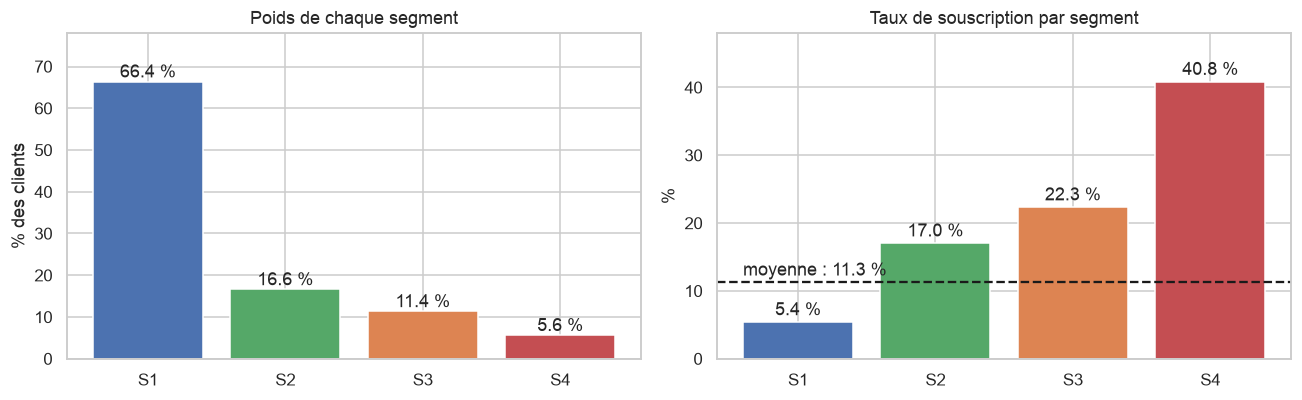

,clients,souscriptions,% des clients,taux de souscription (%),indice (base 100 = moyenne),% des souscriptions
segment,,,,,,
S1,27338,1481,66.4,5.4,48.1,31.9
S2,6841,1165,16.6,17.0,151.2,25.1
S3,4676,1045,11.4,22.3,198.4,22.5
S4,2321,948,5.6,40.8,362.5,20.4


In [4]:
global_rate = 100 * df["souscrit"].mean()
size = df.groupby("segment").agg(clients=("souscrit", "size"), souscriptions=("souscrit", "sum"))
size["% des clients"] = 100 * size["clients"] / len(df)
size["taux de souscription (%)"] = 100 * size["souscriptions"] / size["clients"]
size["indice (base 100 = moyenne)"] = 100 * size["taux de souscription (%)"] / global_rate
size["% des souscriptions"] = 100 * size["souscriptions"] / size["souscriptions"].sum()
size.to_csv(TAB / "05_taille_souscription.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(SEG, size["% des clients"], color=PALETTE)
for i, v in enumerate(size["% des clients"]): axes[0].text(i, v + 1, f"{v:.1f} %", ha="center")
axes[0].set_title("Poids de chaque segment"); axes[0].set_ylabel("% des clients"); axes[0].set_ylim(0, 78)
axes[1].bar(SEG, size["taux de souscription (%)"], color=PALETTE)
axes[1].axhline(global_rate, ls="--", color="k"); axes[1].text(-0.4, global_rate + 1, f"moyenne : {global_rate:.1f} %")
for i, v in enumerate(size["taux de souscription (%)"]): axes[1].text(i, v + 1, f"{v:.1f} %", ha="center")
axes[1].set_title("Taux de souscription par segment"); axes[1].set_ylabel("%"); axes[1].set_ylim(0, 48)
plt.tight_layout(); plt.savefig(FIG / "05_taille_souscription.png", bbox_inches="tight"); plt.show()
size.round(1)

Le taux de souscription est multiplié par **plus de 7** entre S1 et S4, alors que `y` n'a jamais été montrée aux algorithmes : la segmentation capte bien des comportements différents.

## B.2 Variables numériques : moyennes par segment

In [5]:
num_prof = pp.ACTIVE_NUM + ["duration"]
means = df.groupby("segment")[num_prof].mean()
means.loc["Ensemble"] = df[num_prof].mean()
means.round(2).to_csv(TAB / "05_moyennes_segments.csv")
means.round(2)

,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,duration
segment,,,,,,,
S1,40.21,2.71,0.00,93.86,-39.37,4.78,254.02
S2,37.89,2.23,0.00,93.01,-46.02,1.31,264.82
S3,39.40,2.00,1.26,93.27,-43.93,1.63,265.27
S4,45.40,1.79,0.53,92.47,-30.65,0.80,275.66
Ensemble,40.02,2.50,0.17,93.58,-40.50,3.62,258.32


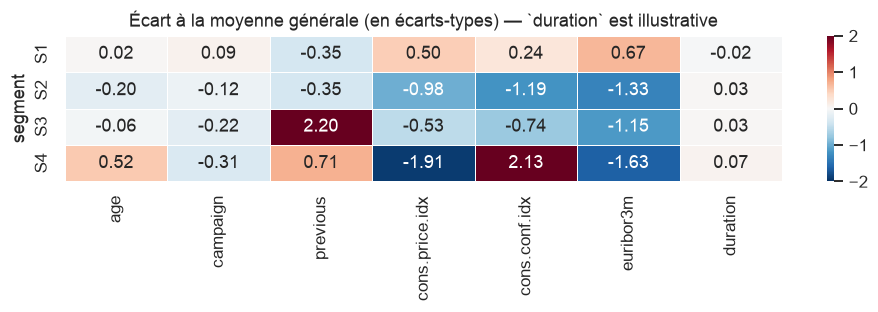

In [6]:
# Écarts à la moyenne en nombre d'écarts-types : ce qui distingue chaque segment
z = (df.groupby("segment")[num_prof].mean() - df[num_prof].mean()) / df[num_prof].std()
plt.figure(figsize=(9, 3))
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, linewidths=.5)
plt.title("Écart à la moyenne générale (en écarts-types) — `duration` est illustrative")
plt.tight_layout(); plt.savefig(FIG / "05_heatmap_profils.png", bbox_inches="tight"); plt.show()

## B.3 Variables catégorielles : modes et répartitions

In [7]:
cat_prof = pp.ACTIVE_CAT + ["month"]
modes = df.groupby("segment")[cat_prof].agg(lambda s: s.mode()[0])
share = df.groupby("segment")[cat_prof].agg(lambda s: f"{100 * s.value_counts(normalize=True).iloc[0]:.0f} %")
(modes + " (" + share + ")").T

segment,S1,S2,S3,S4
job,admin. (26 %),blue-collar (26 %),admin. (27 %),admin. (32 %)
marital,married (64 %),married (54 %),married (55 %),married (59 %)
education,university.degree (33 %),university.degree (32 %),university.degree (34 %),university.degree (48 %)
default,no (74 %),no (87 %),no (88 %),no (97 %)
housing,yes (53 %),yes (60 %),yes (58 %),yes (57 %)
loan,no (85 %),no (84 %),no (85 %),no (86 %)
contact,telephone (50 %),cellular (91 %),cellular (93 %),cellular (88 %)
poutcome,nonexistent (100 %),nonexistent (100 %),failure (79 %),nonexistent (59 %)
contacted_before,no (100 %),no (100 %),no (77 %),no (80 %)
month,may (28 %),may (58 %),may (43 %),aug (33 %)


In [8]:
def pct(col, value):
    """% de clients du segment vérifiant col == value (ou col dans une liste)."""
    vals = value if isinstance(value, list) else [value]
    return 100 * df[col].isin(vals).groupby(df["segment"]).mean()

key = pd.DataFrame({
    "contact sur mobile":                 pct("contact", "cellular"),
    "déjà démarché (campagne passée)":    pct("poutcome", ["failure", "success"]),
    "succès à la campagne passée":        pct("poutcome", "success"),
    "défaut de crédit inconnu":           pct("default", "unknown"),
    "retraité ou étudiant":               pct("job", ["retired", "student"]),
    "ouvrier (blue-collar)":              pct("job", "blue-collar"),
    "diplôme universitaire":              pct("education", "university.degree"),
    "célibataire":                        pct("marital", "single"),
    "60 ans et plus":                     100 * (df["age"] >= 60).groupby(df["segment"]).mean(),
    "prêt immobilier":                    pct("housing", "yes"),
})
key.loc["Ensemble"] = [100 * df["contact"].eq("cellular").mean(), 100 * df["poutcome"].ne("nonexistent").mean(),
                       100 * df["poutcome"].eq("success").mean(), 100 * df["default"].eq("unknown").mean(),
                       100 * df["job"].isin(["retired", "student"]).mean(), 100 * df["job"].eq("blue-collar").mean(),
                       100 * df["education"].eq("university.degree").mean(), 100 * df["marital"].eq("single").mean(),
                       100 * (df["age"] >= 60).mean(), 100 * df["housing"].eq("yes").mean()]
key.round(1).to_csv(TAB / "05_indicateurs_cles.csv")
key.round(1).T

segment,S1,S2,S3,S4,Ensemble
contact sur mobile,49.5,90.8,92.6,88.5,63.5
déjà démarché (campagne passée),0.0,0.0,100.0,40.9,13.7
succès à la campagne passée,0.0,0.0,20.5,17.8,3.3
défaut de crédit inconnu,26.0,12.9,11.7,2.7,20.9
retraité ou étudiant,3.9,7.4,9.2,25.6,6.3
ouvrier (blue-collar),23.3,26.2,20.5,5.3,22.5
diplôme universitaire,33.0,31.9,33.9,47.6,33.7
célibataire,24.8,36.1,34.0,31.3,28.1
60 ans et plus,0.9,3.0,5.0,22.0,2.9
prêt immobilier,52.7,59.9,58.3,56.6,54.8


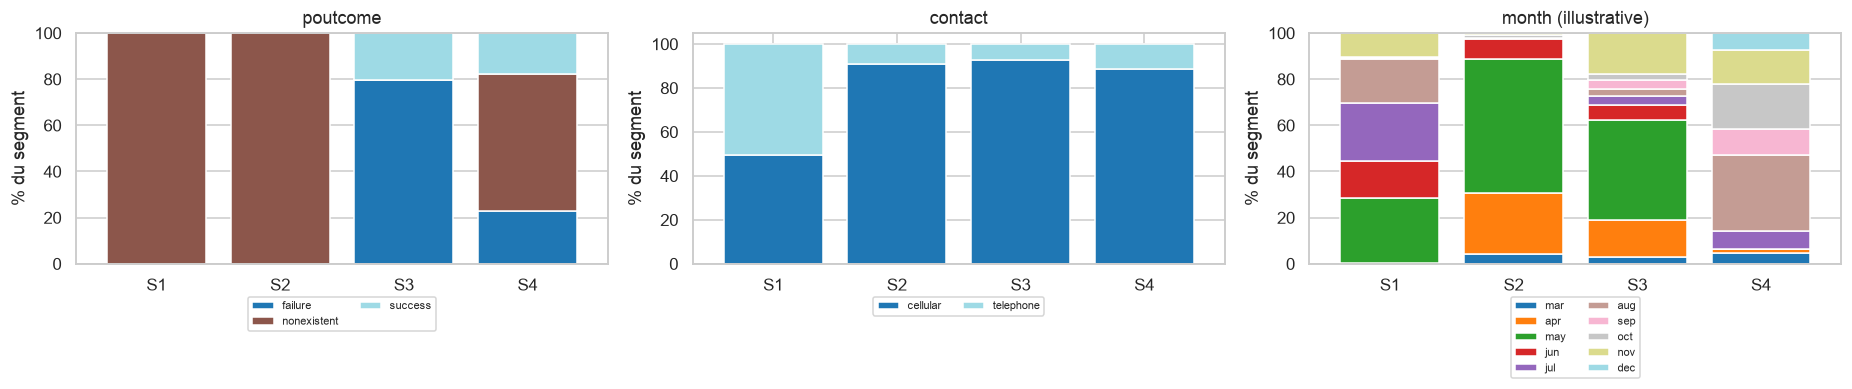

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, col in zip(axes, ["poutcome", "contact", "month"]):
    ct = pd.crosstab(df["segment"], df[col], normalize="index") * 100
    if col == "month":
        ct = ct[["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]]
    ct.plot.bar(stacked=True, ax=ax, colormap="tab20", width=0.8)
    ax.set_title(col + (" (illustrative)" if col == "month" else "")); ax.set_xlabel(""); ax.set_ylabel("% du segment")
    ax.legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12)); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG / "05_categorielles_segments.png", bbox_inches="tight"); plt.show()

## B.4 Radar charts
Huit indicateurs résument chaque segment. Pour les rendre comparables, chacun est ramené entre 0 (valeur du segment le plus bas) et 1 (valeur du segment le plus haut).

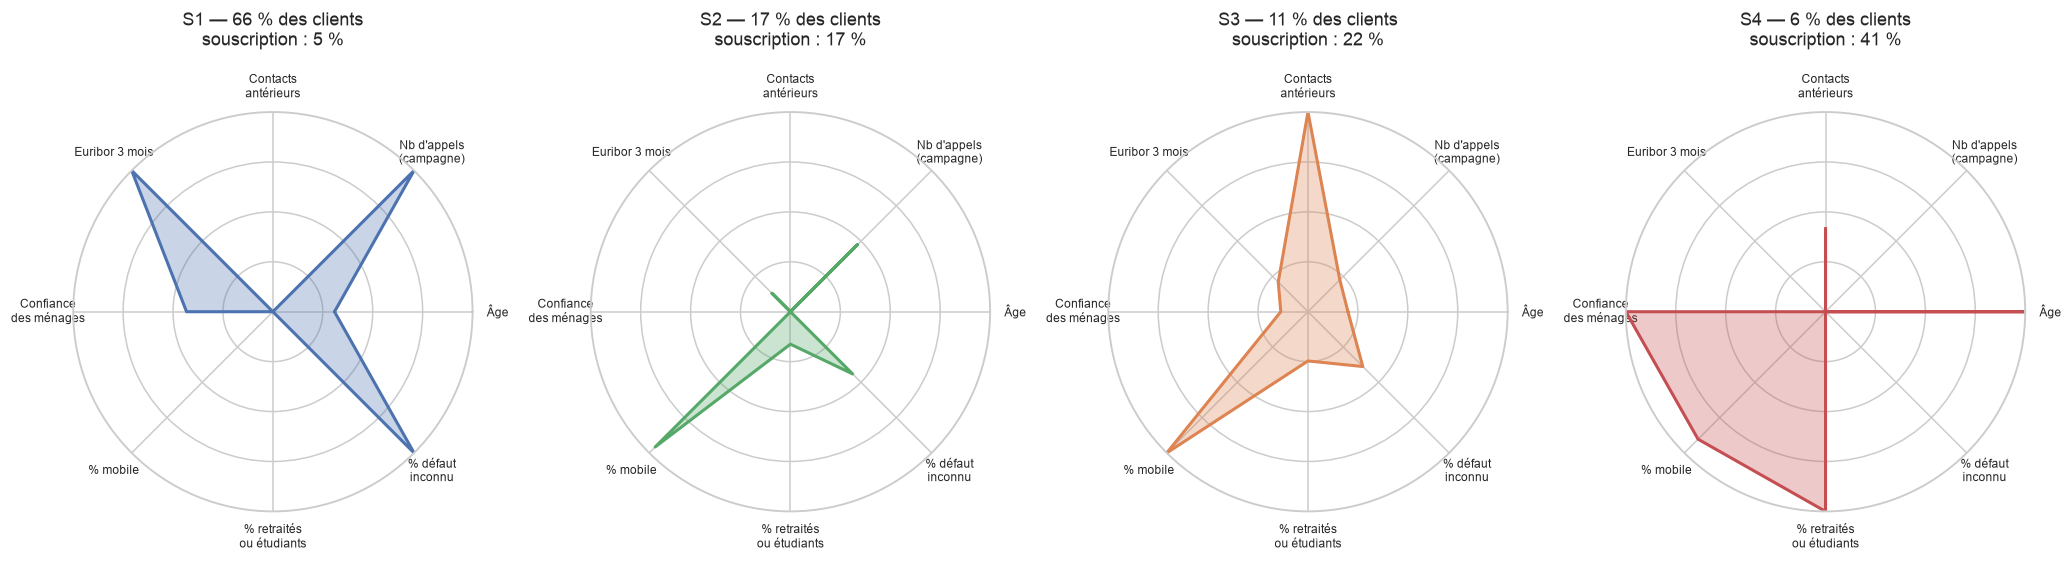

In [10]:
radar = pd.DataFrame({
    "Âge": means.loc[SEG, "age"],
    "Nb d'appels\n(campagne)": means.loc[SEG, "campaign"],
    "Contacts\nantérieurs": means.loc[SEG, "previous"],
    "Euribor 3 mois": means.loc[SEG, "euribor3m"],
    "Confiance\ndes ménages": means.loc[SEG, "cons.conf.idx"],
    "% mobile": key.loc[SEG, "contact sur mobile"],
    "% retraités\nou étudiants": key.loc[SEG, "retraité ou étudiant"],
    "% défaut\ninconnu": key.loc[SEG, "défaut de crédit inconnu"],
})
radar_n = (radar - radar.min()) / (radar.max() - radar.min())
angles = np.linspace(0, 2 * np.pi, radar.shape[1], endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), subplot_kw={"polar": True})
for ax, s, c in zip(axes, SEG, PALETTE):
    vals = radar_n.loc[s].tolist(); vals += vals[:1]
    ax.plot(angles, vals, color=c, lw=2); ax.fill(angles, vals, color=c, alpha=.3)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels(radar.columns, fontsize=8)
    ax.set_yticks([0.25, 0.5, 0.75]); ax.set_yticklabels([]); ax.set_ylim(0, 1)
    ax.set_title(f"{s} — {size.loc[s, '% des clients']:.0f} % des clients\nsouscription : {size.loc[s, 'taux de souscription (%)']:.0f} %", pad=18)
plt.tight_layout(); plt.savefig(FIG / "05_radars.png", bbox_inches="tight"); plt.show()

# Partie C — Fiches d'identité des segments

| | **S1 — Nouveaux prospects, taux élevés** | **S2 — Nouveaux prospects, taux bas** | **S3 — Clients déjà démarchés** | **S4 — Profils réceptifs** |
|---|---|---|---|---|
| **Poids** | 66 % des clients | 17 % | 11 % | 6 % |
| **Taux de souscription** | **5 %** (2 fois moins que la moyenne) | **17 %** (1,5 fois la moyenne) | **22 %** (2 fois la moyenne) | **41 %** (3,6 fois la moyenne) |
| **Historique** | jamais démarchés | jamais démarchés | tous déjà démarchés : 79 % d'échecs, 21 % de succès | mixte : 41 % déjà démarchés |
| **Contexte** | Euribor ≈ 4,8 % ; appels de mai à août | Euribor ≈ 1,3 % ; confiance des ménages au plus bas ; appels en avril-mai | Euribor ≈ 1,6 % | Euribor < 1 % ; confiance des ménages au plus haut ; appels d'août à décembre |
| **Canal** | 50 % fixe / 50 % mobile | mobile (91 %) | mobile (93 %) | mobile (88 %) |
| **Profil** | 40 ans, mariés ; 26 % de défaut « inconnu » ; le plus sollicité (2,7 appels) | le plus jeune (38 ans), 36 % de célibataires | 39 ans, profil socio-démographique moyen | le plus âgé (45 ans ; 22 % de 60 ans et plus) ; 25 % de retraités ou étudiants ; 48 % de diplômés du supérieur ; très peu d'ouvriers |

**Ce qui structure la clientèle.** Trois dimensions ressortent, dans cet ordre : le **contexte économique** au moment du contact (taux élevés ou bas), l'**historique de la relation** (déjà démarché ou non) et, pour S4, le **profil socio-démographique** (seniors, étudiants, diplômés). Les caractéristiques financières du client (prêt immobilier, prêt personnel) ne différencient presque pas les segments.

# Partie D — Recommandations marketing
## D.1 Combien rapporte le ciblage ?
On simule une campagne qui appelle les segments par ordre de priorité (du plus au moins réceptif).

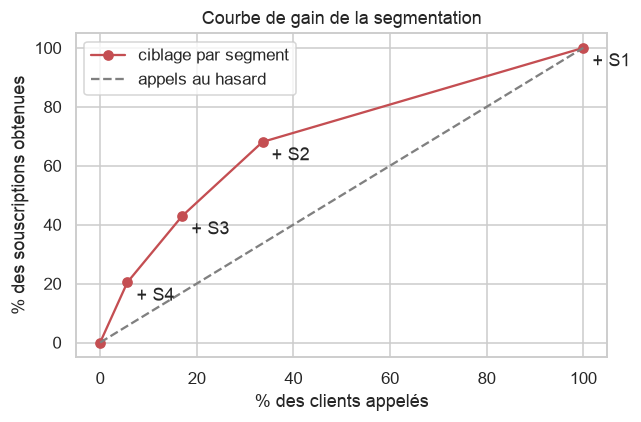

,clients,souscriptions,taux de souscription (%),% cumulé des appels,% cumulé des souscriptions,taux cumulé (%)
segment,,,,,,
S4,2321,948,40.8,5.6,20.4,40.8
S3,4676,1045,22.3,17.0,43.0,28.5
S2,6841,1165,17.0,33.6,68.1,22.8
S1,27338,1481,5.4,100.0,100.0,11.3


In [11]:
gain = size.loc[SEG[::-1], ["clients", "souscriptions", "taux de souscription (%)"]].copy()
gain["% cumulé des appels"] = 100 * gain["clients"].cumsum() / gain["clients"].sum()
gain["% cumulé des souscriptions"] = 100 * gain["souscriptions"].cumsum() / gain["souscriptions"].sum()
gain["taux cumulé (%)"] = 100 * gain["souscriptions"].cumsum() / gain["clients"].cumsum()
gain.to_csv(TAB / "05_courbe_gain.csv")

plt.figure(figsize=(6, 4))
xs = [0] + gain["% cumulé des appels"].tolist(); ys = [0] + gain["% cumulé des souscriptions"].tolist()
plt.plot(xs, ys, "o-", color="#C44E52", label="ciblage par segment")
plt.plot([0, 100], [0, 100], "--", color="grey", label="appels au hasard")
for x, yv, s in zip(xs[1:], ys[1:], gain.index): plt.annotate(f"+ {s}", (x, yv), textcoords="offset points", xytext=(6, -12))
plt.xlabel("% des clients appelés"); plt.ylabel("% des souscriptions obtenues"); plt.title("Courbe de gain de la segmentation"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "05_courbe_gain.png", bbox_inches="tight"); plt.show()
gain.round(1)

**Lecture.** En appelant seulement S4 + S3 + S2, soit **un tiers des clients**, la banque obtient environ **deux tiers des souscriptions**. Le taux de réussite des appels passe de 11 % à plus de 20 %.

## D.2 Une recommandation par segment

| Segment | Recommandation | Justification par les données |
|---|---|---|
| **S4 — Profils réceptifs** (6 %, 41 %) | **Priorité n° 1 : les appeler en premier, avec les conseillers les plus expérimentés.** Offre « épargne sécurisée » orientée seniors et étudiants. Un ou deux appels suffisent. | Taux 3,6 fois supérieur à la moyenne ; segment le moins sollicité (1,8 appel) ; retraités, étudiants et diplômés sur-représentés. |
| **S3 — Clients déjà démarchés** (11 %, 22 %) | **Relance personnalisée selon le résultat précédent.** Anciens succès : proposition de renouvellement, traitée en priorité. Anciens échecs : nouvel argumentaire, jamais le même script. | Tous ont un historique ; 21 % d'anciens succès. Le résultat précédent est la variable la plus discriminante du segment. |
| **S2 — Nouveaux prospects, taux bas** (17 %, 17 %) | **Campagne d'acquisition sur mobile, concentrée sur les périodes de taux bas.** Message : « sécuriser son épargne quand les taux baissent ». Deux appels au maximum. | Taux 1,5 fois supérieur à la moyenne pour un premier contact ; joints à 91 % sur mobile ; clientèle plus jeune et plus souvent célibataire. |
| **S1 — Nouveaux prospects, taux élevés** (66 %, 5 %) | **Réduire la pression téléphonique.** Plafonner à 2 appels, basculer vers des canaux peu coûteux (courriel, SMS, application), et reporter la sollicitation à un contexte plus favorable. | Deux tiers des appels pour un tiers des souscriptions ; segment le plus sollicité (2,7 appels) et le moins réceptif ; la moitié des contacts passe encore par le téléphone fixe. |

**Recommandation transversale.** Les campagnes sont beaucoup plus efficaces quand les taux sont bas. Le **calendrier** des campagnes compte donc autant que le choix des clients : mieux vaut concentrer le budget d'appels sur ces périodes.

# Partie E — Limites et pistes d'amélioration

**Limites**
1. **Structure faible.** Les silhouettes sont modestes (≈ 0,21) : les segments se chevauchent. Ce sont des tendances, pas des catégories étanches.
2. **Le contexte domine.** S1 et S2 se distinguent surtout par la période du contact, pas par ce que le client *est*. Un même client appelé à un autre moment pourrait changer de segment. C'est une information utile pour planifier les campagnes, moins pour connaître les personnes.
3. **Peu de variables sur le client.** Le fichier ne contient ni revenu, ni solde, ni ancienneté : la segmentation socio-démographique reste limitée.
4. **k = 4 est un choix métier.** Statistiquement, la structure la plus nette est à 2 groupes ; le passage à 4 est validé par les indices mais motivé par le besoin de recommandations différenciées.
5. **Ward sur échantillon.** La segmentation est construite sur 4 000 clients puis étendue par le centre le plus proche (accord : 98 %).

**Pistes**
- Refaire la segmentation **sans les variables de contexte** pour obtenir des profils purement « client ».
- Utiliser les points de bruit de DBSCAN (Jour 3) ou une Isolation Forest pour suivre les **clients atypiques**.
- Déployer `assign_segment()` dans une petite application (Streamlit) pour classer un nouveau client en temps réel.
- Reproduire l'étude sur un second jeu de données (segmentation RFM sur *Online Retail*).

## Démonstration : classer un nouveau client

In [12]:
nouveau = pd.DataFrame([{
    "age": 63, "campaign": 1, "previous": 1, "cons.price.idx": 92.9, "cons.conf.idx": -31.0, "euribor3m": 0.9,
    "job": "retired", "marital": "married", "education": "university.degree", "default": "no",
    "housing": "no", "loan": "no", "contact": "cellular", "poutcome": "success", "contacted_before": "yes"}])
s = SEG[assign_segment(nouveau)[0]]
print(f"Segment attribué : {s}  ->  taux de souscription attendu : {size.loc[s, 'taux de souscription (%)']:.0f} %")

Segment attribué : S4  ->  taux de souscription attendu : 41 %


# Conclusion du projet

| Jour | Résultat principal |
|---|---|
| 1 | Données nettoyées, 15 variables actives, deux représentations (one-hot standardisé / mixte), échantillon stratifié de 4 000 clients |
| 2 | La standardisation et le choix de la distance changent les groupes ; Gower pour le mixte ; K-means, K-prototypes et GMM s'accordent à k = 2 |
| 3 | Ward donne des groupes équilibrés ; *single / average / complete* et DBSCAN isolent des atypiques |
| 4 | **CAH de Ward, k = 4** : meilleur compromis entre indices internes, externes et stabilité (ARI bootstrap = 0,93) |
| 5 | 4 segments dont le taux de souscription va de 5 % à 41 % ; un tiers des clients concentre deux tiers des souscriptions |